# Move-IIT-HPE — Experiment A: EventPointPose vs MoveEnet-only vs MoveEnetOFK (corrected native-time alignment)

**Goal.** Evaluate 354 completed EventPointPose `stretch` predictions alongside 708 MoveEnet-only / MoveEnetOFK predictions, across 59 recordings, 6 network rates, 200 Hz nominal output. **No inference is rerun.**

### Evaluation protocol

- Keep **all native prediction timestamps**: the MoveEnet offline runner emits poses at event-packet timestamps, not an exact `0.005s` time lattice. EventPointPose has its own output schedule. Do not modify, round, or interpolate predicted poses.
- For each recording and network period, anchor on the available EventPointPose output timestamps and pair to the **nearest** timestamp for each MoveEnet method, subject to a **2.5 ms** maximum difference and a one-to-one match (no reused predictions). At least 80% of the shortest series must be matched. Record and inspect the resulting alignment lags. Pairing is approximate, **not exact simultaneity**.
- Interpolate the 2D projected GT **separately at each algorithm's actual prediction timestamps**. GT coordinates out of frame / nonfinite are masked *before* interpolation, invalid spans are not bridged, interpolation gaps must be <=50 ms, and GT is never extrapolated.
- The MPJPE and PCK denominators use the **intersection of valid GT joints and finite predictions across all three paired observations**. Each method's errors and PCK torso lengths are computed from the GT **at its own prediction timestamp**; only the eligibility mask is shared.
- PCK@0.2 and PCK@0.4 additionally require both torso joints (indices 1 and 5) to be valid and torso length >=1px **at all three matched times**.
- Curves use pooled valid joint observations; 95% confidence intervals and paired method improvements use recording-level bootstrap with shared draws. Due to EventPointPose warm-up and common eligibility, previously published two-method numbers need not be identical to this matched-population analysis.
- An existing full-run EventPointPose audit (`OK` on all 354 runs) is required; input files are revalidated on read.

**Unverified scientific assumptions:** GT marker-to-skeleton mapping, EventPointPose's output joint order, and zero GT temporal offset. Verify these before treating absolute accuracy as final paper results. EventPointPose uses its original DHP19 pretrained weights without move-iit fine-tuning.


## 1. Inputs and evaluation configuration

MoveEnet and GT paths follow the corrected `MoveIIT_ExpA_2DGT_Analysis.ipynb` protocol. This notebook writes **new output files**, without editing prediction CSVs or previous analyses. A 2.5 ms match means comparing measurements that can differ by up to half of one 200 Hz output period; actual GT coordinates are computed at each native timestamp.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------- Input directories ----------
MOVEENET_BASE = Path('/data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA')
EPP_BASE = Path('/data/MoveEnet_OFK_results/Accuracy/moveiit/EventPointPose/stretch')
EPP_AUDIT = EPP_BASE / 'audit_epp_moveiit.csv'
OUT = MOVEENET_BASE / 'analysis_2d_gt_expa_epp_3methods_v2_native_time'

# ---------- Experiment design ----------
NETWORK_PERIODS = ('0.01', '0.02', '0.05', '0.1', '0.2', '0.5')
EXPECTED_SEQUENCES = 59
OUTPUT_PERIOD_S = 0.005
METHODS = ('moveenet_only', 'moveenet_ofk', 'eventpointpose')

# ---------- GT & time alignment ----------
GT_TIME_OFFSET_S = 0.0  # provisional; matches previous ExpA
SENSOR_WIDTH, SENSOR_HEIGHT = 1280, 720
MAX_GT_GAP_S = 0.050
MIN_TORSO_PX = 1.0
MAX_PAIRING_LAG_S = OUTPUT_PERIOD_S / 2.0  # at most 2.5 ms between EPP and each MoveEnet pose
MIN_COMMON_OVERLAP_FRACTION = 0.80  # fraction of shortest available prediction series

# ---------- Figures & uncertainty ----------
BOOTSTRAP_ITERATIONS = 1000
RANDOM_SEED = 12345
SHOW_CI = True
SAVE_FIGURES = True
FIGURE_FORMATS = ('svg', 'pdf', 'png')
DPI = 300
FIGSIZE = (8.0, 5.0)
COLORS = {'moveenet_only': '#375A9E', 'moveenet_ofk': '#D47A3C', 'eventpointpose': '#3B8B78'}
MARKERS = {'moveenet_only': 's', 'moveenet_ofk': 'o', 'eventpointpose': '^'}
LABELS = {'moveenet_only': 'MoveEnet-only',
          'moveenet_ofk': 'MoveEnetOFK (ROI 35, flow 200 Hz)',
          'eventpointpose': 'EventPointPose (DHP19 pretrained, stretch)'}
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10,
                     'legend.fontsize': 10, 'svg.fonttype': 'none', 'pdf.fonttype': 42})

print('MoveEnet predictions:', MOVEENET_BASE)
print('EventPointPose predictions:', EPP_BASE)
print('Report output:', OUT)
print('Network rates:', [1. / float(x) for x in NETWORK_PERIODS])
print('GT offset =', GT_TIME_OFFSET_S, '(provisional); max nearest-pose pairing lag =', MAX_PAIRING_LAG_S, 's')

MoveEnet predictions: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA
EventPointPose predictions: /data/MoveEnet_OFK_results/Accuracy/moveiit/EventPointPose/stretch
Report output: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_epp_3methods_v2_native_time
Network rates: [100.0, 50.0, 20.0, 10.0, 5.0, 2.0]
GT offset = 0.0 (provisional); max nearest-pose pairing lag = 0.0025 s


## 2. Check experiment inventory and completed EventPointPose audit

The two MoveEnet methods must be present with the previously validated configuration (`moveiit=true`, ROI 35). EventPointPose must have `OK` in its **full-run** audit for all 354 recording/rate pairs. If any check fails, evaluation stops rather than silently selecting a smaller population.

In [2]:
def require(condition, message):
    if not condition:
        raise RuntimeError(message)

manifest_path = MOVEENET_BASE / 'manifest.csv'
config_path = MOVEENET_BASE / 'config.txt'
require(manifest_path.is_file(), 'Missing MoveEnet ExpA manifest: {}'.format(manifest_path))
require(config_path.is_file(), 'Missing MoveEnet config: {}'.format(config_path))
config_text = config_path.read_text()
require('roi=35' in config_text and 'moveiit=true' in config_text,
        'Unexpected MoveEnet experiment config: expected roi=35 and moveiit=true')
manifest = pd.read_csv(manifest_path, dtype=str)
require({'subject', 'sequence', 'ground_truth'} <= set(manifest.columns),
        'Unexpected manifest columns: {}'.format(list(manifest.columns)))
require(len(manifest) == EXPECTED_SEQUENCES, 'Expected {} recordings, got {}'.format(EXPECTED_SEQUENCES, len(manifest)))
require(not manifest.duplicated(['subject', 'sequence']).any(), 'Duplicate MoveEnet recordings in manifest')
require(EPP_AUDIT.is_file(),
        'Missing EPP full-run audit: {}. Run audit_eventpointpose_moveiit.py first.'.format(EPP_AUDIT))
audit = pd.read_csv(EPP_AUDIT, dtype=str)
require({'subject', 'sequence', 'net_period_s', 'status', 'csv_path'} <= set(audit.columns),
        'Unexpected EPP audit columns: {}'.format(list(audit.columns)))
audit['period_key'] = audit.net_period_s.map(lambda p: '{:g}'.format(float(p)))
require(not audit.duplicated(['subject', 'sequence', 'period_key']).any(), 'Duplicate EPP audit entries')
audit_index = audit.set_index(['subject', 'sequence', 'period_key'], drop=False)
expected_keys = {(r.subject, r.sequence, '{:g}'.format(float(p)))
                 for r in manifest.itertuples(index=False) for p in NETWORK_PERIODS}
require(set(audit_index.index) == expected_keys,
        'EPP audit inventory differs from MoveEnet manifest: missing={} extra={}'.format(
            sorted(expected_keys - set(audit_index.index))[:8],
            sorted(set(audit_index.index) - expected_keys)[:8]))
bad = audit[audit.status != 'OK']
require(bad.empty, 'EPP audit found non-OK runs:\n{}'.format(bad[['subject','sequence','net_period_s','status']].head(15).to_string(index=False)))
print('Audit: {} EventPointPose runs OK ({} sequences × {} periods)'.format(
    len(audit), len(manifest), len(NETWORK_PERIODS)))
display(manifest[['subject', 'sequence', 'ground_truth']].head(6))

Audit: 354 EventPointPose runs OK (59 sequences × 6 periods)


,subject,sequence,ground_truth
0,luna,box_f1,/data/move-iit-it_testing/GT/P1_luna/box_f1_jo...
1,luna,box_s1,/data/move-iit-it_testing/GT/P1_luna/box_s1_jo...
2,luna,drum_f1,/data/move-iit-it_testing/GT/P1_luna/drum_f1_j...
3,luna,drum_s1,/data/move-iit-it_testing/GT/P1_luna/drum_s1_j...
4,luna,march_f1,/data/move-iit-it_testing/GT/P1_luna/march_f1_...
5,luna,march_s1,/data/move-iit-it_testing/GT/P1_luna/march_s1_...


## 3. Load predictions and GT; pair **native** timestamps (no prediction interpolation)

All three algorithms export 13 joints in the 1280x720 sensor frame. EventPointPose pose output starts after FIFO warm-up, while MoveEnet's C++ writer uses event-packet timestamps, which are not exact multiples of 5 ms. Pair the nearest time-adjacent samples with a 2.5 ms bound and **interpolate GT separately for each matched native timestamp**. Both the pairing lags and overlap are reported for each recording/rate. The projection-marker-to-HPE mapping is the *provisional* one from corrected ExpA. EventPointPose's output order is also unverified.

In [3]:
JOINT_NAMES = (
    'Head', 'Right shoulder', 'Left shoulder', 'Right elbow', 'Left elbow',
    'Left hip', 'Right hip', 'Right wrist', 'Left wrist',
    'Right knee', 'Left knee', 'Right ankle', 'Left ankle'
)
PROJECTION_TO_MOVEENET = np.array([0, 1, 2, 3, 4, 8, 7, 5, 6, 9, 10, 11, 12])  # PROVISIONAL
PRED_COLS = ['timestamp', 'latency'] + [
    'joint{}_{}'.format(j, a) for j in range(13) for a in ('x', 'y')]
GT_SCHEMAS = {}


def load_gt(path):
    df = pd.read_csv(path, encoding='utf-8-sig')
    df.columns = [str(c).strip() for c in df.columns]
    df = df.loc[:, ~df.columns.str.match(r'^Unnamed: \d+$')]
    time_col = ('event_timestamp' if 'event_timestamp' in df.columns else
                'timestamp' if 'timestamp' in df.columns else df.columns[0])
    coord_cols = [c for c in df.columns if c != time_col]
    require(len(coord_cols) == 26, 'GT must have 26 coordinate columns: {}'.format(path))
    for j in range(13):
        x, y = coord_cols[2*j:2*j+2]
        require(x.lower().endswith('_x') and y.lower().endswith('_y') and x[:-2].lower() == y[:-2].lower(),
                'GT x/y mismatch {}: {}, {}'.format(path, x, y))
    GT_SCHEMAS.setdefault(tuple(coord_cols), []).append(str(path))
    t = pd.to_numeric(df[time_col], errors='raise').to_numpy(dtype=float)
    xy = df[coord_cols].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float).reshape(-1, 13, 2)
    require(len(t) >= 2 and np.isfinite(t).all() and np.all(np.diff(t) > 0),
            'GT timestamps must increase: {}'.format(path))
    native_order = all(coord_cols[2*j:2*j+2] == ['joint{}_x'.format(j), 'joint{}_y'.format(j)]
                       for j in range(13))
    xy = xy[:, (np.arange(13) if native_order else PROJECTION_TO_MOVEENET), :]
    finite = np.isfinite(xy).all(axis=2)
    valid = (finite & (xy[..., 0] >= 0) & (xy[..., 0] < SENSOR_WIDTH) &
             (xy[..., 1] >= 0) & (xy[..., 1] < SENSOR_HEIGHT))
    return t, xy, valid, finite


def load_prediction(path):
    require(path.is_file(), 'Missing prediction: {}'.format(path))
    df = pd.read_csv(path)
    require(list(df.columns) == PRED_COLS, 'Unexpected 28-column prediction schema: {}'.format(path))
    ts = pd.to_numeric(df.timestamp, errors='raise').to_numpy(dtype=float)
    xy = df[PRED_COLS[2:]].apply(pd.to_numeric, errors='coerce').to_numpy(dtype=float).reshape(-1,13,2)
    require(len(ts) >= 2 and np.isfinite(ts).all() and np.all(np.diff(ts) > 0),
            'Prediction timestamps must strictly increase: {}'.format(path))
    return ts, xy


def masked_linear_gt(t_query, t_gt, xy_gt, valid_gt, max_gap_s=MAX_GT_GAP_S):
    # Same masked interpolation as corrected MoveIIT_ExpA_2DGT_Analysis v2.
    q = np.asarray(t_query, dtype=float) + GT_TIME_OFFSET_S
    t_gt = np.asarray(t_gt, dtype=float)
    valid_gt = np.asarray(valid_gt, dtype=bool)
    n, nj = len(q), xy_gt.shape[1]
    result = np.full((n, nj, 2), np.nan, dtype=float)
    mask = np.zeros((n, nj), dtype=bool)
    inside = np.isfinite(q) & (q >= t_gt[0]) & (q <= t_gt[-1])
    if not inside.any():
        return result, mask, inside
    indices = np.flatnonzero(inside)
    query = q[indices]
    right = np.searchsorted(t_gt, query, side='left')
    right_clamped = np.minimum(right, len(t_gt)-1)
    exact = (right < len(t_gt)) & (np.abs(t_gt[right_clamped] - query) <= 1e-9)
    if exact.any():
        idx_q, idx_gt = indices[exact], right_clamped[exact]
        v = valid_gt[idx_gt]
        result[idx_q] = np.where(v[..., None], xy_gt[idx_gt], np.nan)
        mask[idx_q] = v
    between = ~exact
    if between.any():
        idx_q = indices[between]
        hi = right_clamped[between]
        lo = hi-1
        dt = t_gt[hi]-t_gt[lo]
        okay_time = (dt > 0) & (dt <= max_gap_s)
        v = valid_gt[lo] & valid_gt[hi] & okay_time[:,None]
        alpha = ((query[between]-t_gt[lo])/dt)[:,None,None]
        interp = xy_gt[lo] + alpha*(xy_gt[hi]-xy_gt[lo])
        result[idx_q] = np.where(v[...,None], interp, np.nan)
        mask[idx_q] = v
    return result, mask, inside



def nearest_native_index(reference_ts, candidate_ts):
    """Nearest index in a strictly increasing series; unmatched values are flagged.

    No timestamp is rounded or changed. A one-to-one match is imposed later.
    """
    hi = np.searchsorted(candidate_ts, reference_ts, side='left')
    left = np.clip(hi - 1, 0, len(candidate_ts) - 1)
    right = np.clip(hi, 0, len(candidate_ts) - 1)
    take_left = (np.abs(candidate_ts[left] - reference_ts) <=
                 np.abs(candidate_ts[right] - reference_ts))
    idx = np.where(take_left, left, right)
    lag = candidate_ts[idx] - reference_ts
    return idx, lag


def align_three(predictions, paths):
    """One-to-one nearest-neighbour pairing on actual timestamps.

    EventPointPose serves as the temporal anchor only to determine *which*
    observations pair together. GT will later be interpolated at the native
    timestamp of EACH prediction, rather than at this anchor for all methods.
    """
    ref_times = predictions['eventpointpose'][0]
    selected = {'eventpointpose': np.arange(len(ref_times), dtype=np.int64)}
    lag_by_method = {}
    keep = np.ones(len(ref_times), dtype=bool)

    for method in METHODS[:2]:
        ts = predictions[method][0]
        indices, lags = nearest_native_index(ref_times, ts)
        valid = np.abs(lags) <= (MAX_PAIRING_LAG_S + 1e-9)

        # Reject ambiguous many-to-one correspondences rather than reusing a
        # MoveEnet prediction for two different EventPointPose output slots.
        unique_indices, inverse, counts = np.unique(indices[valid],
                                                     return_inverse=True,
                                                     return_counts=True)
        unique_match = np.zeros(len(ref_times), dtype=bool)
        unique_match[np.flatnonzero(valid)] = counts[inverse] == 1
        keep &= valid & unique_match
        selected[method] = indices
        lag_by_method[method] = lags

    ref_indices = selected['eventpointpose'][keep]
    lengths = [len(predictions[m][0]) for m in METHODS]
    overlap = len(ref_indices) / min(lengths)
    require(len(ref_indices) >= 2 and overlap >= MIN_COMMON_OVERLAP_FRACTION,
            ('Only {:.1%} one-to-one nearest matches with lag <= {:.2f}ms, '
             'for {}. Check time origins and per-file rates.').format(
                 overlap, MAX_PAIRING_LAG_S * 1000.0, paths))

    aligned = {}
    for method in METHODS:
        indices = selected[method][keep]
        require(np.all(np.diff(indices) > 0),
                'Non-increasing/duplicate aligned prediction indices for {}'.format(paths[method]))
        aligned[method] = (predictions[method][0][indices],
                           predictions[method][1][indices])

    lags = {
        method: {
            'mean_absolute_ms': float(np.abs(lag_by_method[method][keep]).mean() * 1000.0),
            'max_absolute_ms': float(np.abs(lag_by_method[method][keep]).max() * 1000.0),
            'median_signed_ms': float(np.median(lag_by_method[method][keep]) * 1000.0),
        }
        for method in METHODS[:2]
    }
    max_abs_lag_s = max(lags[m]['max_absolute_ms'] for m in METHODS[:2]) / 1000.0
    return aligned['eventpointpose'][0], aligned, overlap, max_abs_lag_s, lengths, lags


def safe_ratio(num, den, scale=1.0):
    return float(scale * num / den) if den > 0 else float('nan')

### Synthetic protocol tests

These tests verify masked GT interpolation (including invalid marker gaps), native irregular timestamps, bounded one-to-one pairing, and rejection of shifted time origins. They do **not** certify actual dataset files or the anatomical joint mapping.

In [4]:
def test_protocol_helpers():
    t = np.array([0.00, 0.01, 0.02, 0.03])
    xy = np.zeros((4, 13, 2), dtype=float)
    xy[:, :, 0] = 100 + np.arange(4)[:, None] * 10
    xy[:, :, 1] = 200
    valid = np.ones((4, 13), dtype=bool)
    valid[1, 2] = False
    q = np.array([-0.001, 0.0, 0.005, 0.01, 0.015, 0.02, 0.025, 0.031])
    out, mask, inside = masked_linear_gt(q, t, xy, valid)
    assert not mask[0].any() and not mask[-1].any()
    assert mask[1].all() and mask[5].all()
    assert not mask[2, 2] and not mask[3, 2] and not mask[4, 2] and mask[6, 2]
    assert abs(out[2, 0, 0] - 105.0) < 1e-6
    _, m, _ = masked_linear_gt([.05], [0., .1],
                                np.zeros((2, 13, 2)), np.ones((2, 13), bool))
    assert not m.any()

    # Regression for the actual error: MoveEnet timestamps have irregular
    # packet-event phases and can deviate by 2.48 ms from multiples of 5 ms.
    base = np.arange(40) * OUTPUT_PERIOD_S
    irregular = base + 0.00135 + 0.00112 * np.sin(np.arange(40) * 0.55)
    irregular2 = irregular + 0.00010
    pred = {
        'moveenet_only': (irregular, np.zeros((40, 13, 2))),
        'moveenet_ofk': (irregular2, np.ones((40, 13, 2))),
        'eventpointpose': (base[3:], np.ones((37, 13, 2)) * 2),
    }
    anchor, aligned, overlap, deviation, lengths, lags = align_three(pred, {m: m for m in METHODS})
    assert len(anchor) >= 30 and overlap > .80 and deviation <= MAX_PAIRING_LAG_S + 1e-9
    assert lengths == [40, 40, 37]
    assert np.all(aligned['eventpointpose'][1] == 2)
    assert np.all(np.diff(aligned['moveenet_only'][0]) > 0)
    assert np.max(np.abs(aligned['moveenet_only'][0] - anchor)) <= MAX_PAIRING_LAG_S + 1e-9
    assert lags['moveenet_only']['max_absolute_ms'] > 0.5
    # A large offset must fail instead of silently shifting predictions.
    bad = dict(pred)
    bad['moveenet_only'] = (irregular + 0.2, pred['moveenet_only'][1])
    try:
        align_three(bad, {m: m for m in METHODS})
    except RuntimeError:
        pass
    else:
        raise AssertionError('Unrelated time origins were incorrectly accepted')
    print('PASS: GT interpolation, native timestamp pairing, one-to-one matches, offset rejection')

test_protocol_helpers()

PASS: GT interpolation, native timestamp pairing, one-to-one matches, offset rejection


## 4. Evaluate three methods using matched observations at their **actual** timestamps

For every sequence and rate, match nearby outputs once (<=2.5 ms), then compute GT coordinates independently at the matched timestamp of each algorithm. The common MPJPE mask retains a joint only when all three predicted coordinates are finite and the GT is valid at **all three native times**. PCK additionally requires all three native-time GT torso lengths to be valid. Pairwise denominator equality is then guaranteed by construction. Report mean/max native time lag and population overlap, since *paired* does not mean *identical timestamp*.

In [5]:
rows, joint_rows, gt_quality_rows, alignment_rows = [], [], [], []
for i, rec in enumerate(manifest.itertuples(index=False), 1):
    subject, sequence = rec.subject, rec.sequence
    gt_path = Path(rec.ground_truth)
    require(gt_path.is_file(), 'Missing GT: {}'.format(gt_path))
    gt_t, gt_xy, gt_valid, gt_finite = load_gt(gt_path)
    gt_quality_rows.append({
        'subject':subject, 'sequence':sequence, 'gt_rows':len(gt_t),
        'gt_start_s':float(gt_t[0]), 'gt_end_s':float(gt_t[-1]),
        'gt_mean_hz':float((len(gt_t)-1)/(gt_t[-1]-gt_t[0])),
        'gt_nonfinite_annotations':int((~gt_finite).sum()),
        'gt_out_of_frame_annotations':int((gt_finite & ~gt_valid).sum()),
        'gt_valid_annotations':int(gt_valid.sum()),
        'gt_total_annotations':int(gt_valid.size),
    })
    stem = '{}__{}__atis-s'.format(subject,sequence)
    for period_tag in NETWORK_PERIODS:
        period, tag = float(period_tag), period_tag.replace('.', 'p')
        move_dir = MOVEENET_BASE / 'raw' / 'fp_0p005' / ('np_' + tag)
        paths = {
            method: move_dir / '{}_{}_np_{}_fp_0p005.csv'.format(stem,method,tag)
            for method in METHODS[:2]
        }
        paths['eventpointpose'] = EPP_BASE / 'raw' / '{}__epp_stretch_np_{}.csv'.format(stem,tag)
        # Check original MoveEnet completion and EventPointPose full-run audit.
        for method in METHODS[:2]:
            name = '{}_{}_np_{}_fp_0p005'.format(stem, method, tag)
            log_path = MOVEENET_BASE / 'logs' / (name + '.log')
            require(log_path.is_file() and 'Finished processing event file.' in log_path.read_text(errors='replace'),
                    'Missing or incomplete MoveEnet ExpA run: {}'.format(log_path))
        key = (subject, sequence, '{:g}'.format(period))
        audited = audit_index.loc[key]
        require(audited.status == 'OK', 'Non-OK EPP audit for {}'.format(key))
        require(Path(audited.csv_path).resolve() == paths['eventpointpose'].resolve(),
                'EPP audit CSV path differs: {}'.format(key))
        predictions = {m:load_prediction(paths[m]) for m in METHODS}
        require(len(predictions['eventpointpose'][0]) == int(audited.csv_rows),
                'EventPointPose audit row count changed after validation: {}'.format(key))
        require(np.isclose(predictions['eventpointpose'][0][0], float(audited.first_ts_s), atol=1e-5)
                and np.isclose(predictions['eventpointpose'][0][-1], float(audited.last_ts_s), atol=1e-5),
                'EventPointPose audit first/last timestamp changed: {}'.format(key))
        t_common, aligned, overlap, deviation, native_lengths, pair_lags = align_three(predictions, paths)

        # Interpolate GT to each algorithm's OWN native prediction timestamps.
        # This avoids scoring a pose at a time it was not actually produced.
        gt_for_method = {}
        gt_valid_for_method = {}
        gt_in_interval = {}
        common_joint_mask = np.ones((len(t_common), 13), dtype=bool)
        torso_valid_all = np.ones(len(t_common), dtype=bool)
        torso_for_method = {}
        for method in METHODS:
            t_native, xy_native = aligned[method]
            g, g_valid, time_ok = masked_linear_gt(t_native, gt_t, gt_xy, gt_valid)
            gt_for_method[method] = g
            gt_valid_for_method[method] = g_valid
            gt_in_interval[method] = time_ok
            prediction_valid = np.isfinite(xy_native).all(axis=2)
            common_joint_mask &= g_valid & prediction_valid
            native_torso_valid = g_valid[:, 1] & g_valid[:, 5]
            safe_torso_gt = np.where(g_valid[..., None], g, 0.0)
            torso = np.linalg.norm(safe_torso_gt[:, 1] - safe_torso_gt[:, 5], axis=1)
            torso_valid_all &= native_torso_valid & np.isfinite(torso) & (torso >= MIN_TORSO_PX)
            torso_for_method[method] = torso
        joint_mask = common_joint_mask
        pck_mask = joint_mask & torso_valid_all[:, None]
        joint_count, pck_count = int(joint_mask.sum()), int(pck_mask.sum())
        require(joint_count > 0 and pck_count > 0,
                'No usable shared ground truth for {} {} {}'.format(subject, sequence, period))
        all_times_in_gt = np.logical_and.reduce([gt_in_interval[m] for m in METHODS])
        alignment_rows.append({
            'subject':subject,'sequence':sequence,'net_period_s':period,'net_hz':1./period,
            'sample_id':'{}/{}'.format(subject,sequence),
            'only_native_rows':native_lengths[0], 'ofk_native_rows':native_lengths[1],
            'epp_native_rows':native_lengths[2], 'common_rows':len(t_common),
            'common_fraction_of_shortest':overlap,
            'common_first_s':float(t_common[0]),'common_last_s':float(t_common[-1]),
            'max_timestamp_alignment_error_s':deviation,  # nearest-pair lag, NOT deviation from 5 ms grid
            'only_mean_absolute_pair_lag_ms':pair_lags['moveenet_only']['mean_absolute_ms'],
            'only_max_absolute_pair_lag_ms':pair_lags['moveenet_only']['max_absolute_ms'],
            'only_median_signed_pair_lag_ms':pair_lags['moveenet_only']['median_signed_ms'],
            'ofk_mean_absolute_pair_lag_ms':pair_lags['moveenet_ofk']['mean_absolute_ms'],
            'ofk_max_absolute_pair_lag_ms':pair_lags['moveenet_ofk']['max_absolute_ms'],
            'ofk_median_signed_pair_lag_ms':pair_lags['moveenet_ofk']['median_signed_ms'],
            'gt_time_covered_rows':int(all_times_in_gt.sum()),
            'gt_any_valid_rows':int(joint_mask.any(axis=1).sum()),
            'torso_valid_rows':int(torso_valid_all.sum()),
            'mpjpe_joint_observations':joint_count,'pck_joint_observations':pck_count,
        })
        for method in METHODS:
            g = gt_for_method[method]
            g_safe = np.where(joint_mask[..., None], g, 0.0)
            predicted = np.where(joint_mask[..., None], aligned[method][1], 0.0)
            errors = np.linalg.norm(predicted-g_safe,axis=2)
            torso = torso_for_method[method]
            hits02 = (errors <= 0.2*torso[:,None]) & pck_mask
            hits04 = (errors <= 0.4*torso[:,None]) & pck_mask
            err_sum,n02,n04 = float(errors[joint_mask].sum()),int(hits02.sum()),int(hits04.sum())
            rows.append({
                'subject':subject,'sequence':sequence,'sample_id':'{}/{}'.format(subject,sequence),
                'method':method,'net_period_s':period,'net_hz':1./period,'output_hz':200,
                'matched_rows':len(t_common),'valid_mpjpe_joints':joint_count,
                'valid_pck_joints':pck_count,'sum_error_px':err_sum,
                'correct_pck02':n02,'correct_pck04':n04,
                'mpjpe_px':safe_ratio(err_sum,joint_count),
                'pck02_percent':safe_ratio(n02,pck_count,100.),
                'pck04_percent':safe_ratio(n04,pck_count,100.),
            })
            for j,label in enumerate(JOINT_NAMES):
                jm,jp = joint_mask[:,j],pck_mask[:,j]
                joint_rows.append({
                    'subject':subject,'sequence':sequence,'sample_id':'{}/{}'.format(subject,sequence),
                    'net_period_s':period,'net_hz':1./period,'method':method,
                    'joint_id':j,'joint':label,
                    'valid_mpjpe_joints':int(jm.sum()),'valid_pck_joints':int(jp.sum()),
                    'sum_error_px':float(errors[jm,j].sum()),
                    'correct_pck02':int(hits02[:,j].sum()),
                })
    print('[{:02d}/{:02d}] {}/{}: all rates and three methods evaluated'.format(
        i,len(manifest),subject,sequence))

samples = pd.DataFrame(rows)
joints = pd.DataFrame(joint_rows)
gt_quality = pd.DataFrame(gt_quality_rows)
alignment = pd.DataFrame(alignment_rows)
require(len(samples) == len(manifest)*len(NETWORK_PERIODS)*len(METHODS),
        'Missing method/rate/sample rows in evaluation')
require(len(alignment) == len(manifest)*len(NETWORK_PERIODS), 'Missing alignment rows')
print('Method/rate/recording evaluations:',len(samples))
print('Distinct GT schemas:',len(GT_SCHEMAS))
for schema, examples in GT_SCHEMAS.items():
    print('  {} sequences, example {}, markers: {}'.format(
        len(examples),Path(examples[0]).name, ', '.join(schema[::2])))
display(samples[['sample_id','net_hz','method','mpjpe_px','pck02_percent','valid_mpjpe_joints']].head(9).round(3))

[01/59] luna/box_f1: all rates and three methods evaluated
[02/59] luna/box_s1: all rates and three methods evaluated
[03/59] luna/drum_f1: all rates and three methods evaluated
[04/59] luna/drum_s1: all rates and three methods evaluated
[05/59] luna/march_f1: all rates and three methods evaluated
[06/59] luna/march_s1: all rates and three methods evaluated
[07/59] luna/mix_f1: all rates and three methods evaluated
[08/59] luna/mix_s1: all rates and three methods evaluated
[09/59] luna/pour_f1: all rates and three methods evaluated
[10/59] luna/pour_s1: all rates and three methods evaluated
[11/59] luna/side_f1: all rates and three methods evaluated
[12/59] luna/side_s1: all rates and three methods evaluated
[13/59] luna/sit-drum_f1: all rates and three methods evaluated
[14/59] luna/sit-drum_s1: all rates and three methods evaluated
[15/59] luna/sit-mix_f1: all rates and three methods evaluated
[16/59] luna/sit-mix_s1: all rates and three methods evaluated
[17/59] luna/sit-pour_f1: al

,sample_id,net_hz,method,mpjpe_px,pck02_percent,valid_mpjpe_joints
0,luna/box_f1,100.0,moveenet_only,54.702,31.592,27818
1,luna/box_f1,100.0,moveenet_ofk,51.812,32.564,27818
2,luna/box_f1,100.0,eventpointpose,83.459,12.926,27818
3,luna/box_f1,50.0,moveenet_only,54.512,31.538,27811
4,luna/box_f1,50.0,moveenet_ofk,51.539,32.891,27811
5,luna/box_f1,50.0,eventpointpose,83.189,12.900,27811
6,luna/box_f1,20.0,moveenet_only,54.412,31.803,27818
7,luna/box_f1,20.0,moveenet_ofk,51.626,32.887,27818
8,luna/box_f1,20.0,eventpointpose,83.913,13.111,27818


## 5. Aggregate pooled MPJPE, PCK and recording-bootstrap confidence intervals

All three model columns contain one-to-one paired near-time observations in the same recording order at every network frequency, and bootstrap resamples entire recordings. This retains temporal correlation within a recording rather than treating thousands of adjacent 200 Hz outputs as independent samples.

In [6]:
rng = np.random.default_rng(RANDOM_SEED)
summary_rows = []
resample_indices = {}  # one paired set of sequence draws per frequency
ordered_groups = {}


def ci95(values):
    a = np.asarray(values,float)
    a = a[np.isfinite(a)]
    return (float('nan'),float('nan')) if len(a) == 0 else tuple(float(x) for x in np.quantile(a,[.025,.975]))


def bootstrap_fraction(nums, dens, draws, scale=1.0):
    a = np.asarray(nums,dtype=float)[draws].sum(axis=1)
    b = np.asarray(dens,dtype=float)[draws].sum(axis=1)
    return np.divide(scale*a,b,out=np.full(len(draws),np.nan),where=b>0)

for period in [float(x) for x in NETWORK_PERIODS]:
    period_groups = {}
    for method in METHODS:
        grp = samples[(samples.net_period_s == period) & (samples.method == method)].sort_values('sample_id').reset_index(drop=True)
        require(len(grp) == len(manifest), 'Missing {} data at {}'.format(method,period))
        period_groups[method] = grp
    ref = period_groups[METHODS[0]]
    for method in METHODS[1:]:
        other = period_groups[method]
        require(ref.sample_id.equals(other.sample_id), 'Unpaired sequences: {} {}'.format(method,period))
        require(np.array_equal(ref.valid_mpjpe_joints,other.valid_mpjpe_joints) and
                np.array_equal(ref.valid_pck_joints,other.valid_pck_joints) and
                np.array_equal(ref.matched_rows,other.matched_rows),
                'Metric denominators or common timestamps differ between algorithms: {} {}'.format(method,period))
    draws = rng.integers(0,len(ref),size=(BOOTSTRAP_ITERATIONS,len(ref)))
    resample_indices[period] = draws
    ordered_groups[period] = period_groups
    for method in METHODS:
        grp = period_groups[method]
        total_err = grp.sum_error_px.sum()
        nj = grp.valid_mpjpe_joints.sum()
        npck = grp.valid_pck_joints.sum()
        boot_mpjpe = bootstrap_fraction(grp.sum_error_px,grp.valid_mpjpe_joints,draws)
        boot_pck = bootstrap_fraction(grp.correct_pck02,grp.valid_pck_joints,draws,100.)
        mp_lo,mp_hi = ci95(boot_mpjpe)
        p_lo,p_hi = ci95(boot_pck)
        summary_rows.append({
            'net_period_s':period,'net_hz':1./period,'method':method,
            'n_sequences':len(grp), 'valid_mpjpe_joints':int(nj),'valid_pck_joints':int(npck),
            'mpjpe_px':safe_ratio(total_err,nj),
            'pck02_percent':safe_ratio(grp.correct_pck02.sum(),npck,100.),
            'pck04_percent':safe_ratio(grp.correct_pck04.sum(),npck,100.),
            'mpjpe_px_ci_low':mp_lo, 'mpjpe_px_ci_high':mp_hi,
            'pck02_percent_ci_low':p_lo, 'pck02_percent_ci_high':p_hi,
            'macro_mpjpe_px':float(grp.mpjpe_px.mean()),
            'macro_pck02_percent':float(grp.pck02_percent.mean()),
        })
summary = pd.DataFrame(summary_rows).sort_values(['net_hz','method']).reset_index(drop=True)
display(summary[['net_hz','method','n_sequences','mpjpe_px','pck02_percent','pck04_percent',
                 'valid_mpjpe_joints','valid_pck_joints']].round(3))

,net_hz,method,n_sequences,mpjpe_px,pck02_percent,pck04_percent,valid_mpjpe_joints,valid_pck_joints
0,2.0,eventpointpose,59,104.616,14.769,38.132,1520576,1519685
1,2.0,moveenet_ofk,59,62.696,33.422,64.892,1520576,1519685
2,2.0,moveenet_only,59,67.781,29.710,60.270,1520576,1519685
3,5.0,eventpointpose,59,101.910,15.671,40.372,1548868,1547739
4,5.0,moveenet_ofk,59,59.636,35.813,67.041,1548868,1547739
5,5.0,moveenet_only,59,62.632,34.281,64.848,1548868,1547739
6,10.0,eventpointpose,59,101.216,15.973,41.007,1552638,1551418
7,10.0,moveenet_ofk,59,59.215,36.583,67.739,1552638,1551418
8,10.0,moveenet_only,59,61.899,35.831,65.998,1552638,1551418
9,20.0,eventpointpose,59,101.243,16.058,41.093,1555432,1554135


## 6. Paired improvements and 95% bootstrap confidence intervals

Positive improvement means the first method outperforms the comparator: MPJPE improvement is **comparator minus method** (px), PCK improvement is **method minus comparator** (percentage points). Zero is the no-difference line. These intervals account for pairing because both methods use the same recording bootstrap draw and an identical validity mask/denominator, although native prediction timestamps differ by up to 2.5ms.

In [7]:
PAIRINGS = (
    ('moveenet_ofk','moveenet_only'),
    ('eventpointpose','moveenet_only'),
    ('moveenet_ofk','eventpointpose'),
)
delta_rows = []
for period in [float(x) for x in NETWORK_PERIODS]:
    groups = ordered_groups[period]
    draw = resample_indices[period]
    for first, baseline in PAIRINGS:
        a, b = groups[first], groups[baseline]
        denom_j,denom_p = a.valid_mpjpe_joints.sum(),a.valid_pck_joints.sum()
        mp_delta = (b.sum_error_px.sum()-a.sum_error_px.sum())/denom_j
        pck_delta = 100.*(a.correct_pck02.sum()-b.correct_pck02.sum())/denom_p
        mp_boot = bootstrap_fraction(b.sum_error_px-a.sum_error_px, a.valid_mpjpe_joints,draw)
        pck_boot = bootstrap_fraction(a.correct_pck02-b.correct_pck02,a.valid_pck_joints,draw,100.)
        mp_lo,mp_hi = ci95(mp_boot)
        p_lo,p_hi = ci95(pck_boot)
        delta_rows.append({
            'net_period_s':period,'net_hz':1./period,'method':first,'baseline':baseline,
            'n_sequences':len(a),
            'mpjpe_improvement_px':float(mp_delta), 'mpjpe_ci_low':mp_lo,'mpjpe_ci_high':mp_hi,
            'pck02_improvement_pp':float(pck_delta),'pck02_ci_low':p_lo,'pck02_ci_high':p_hi,
            'n_seq_better_mpjpe':int((a.mpjpe_px.to_numpy() < b.mpjpe_px.to_numpy()).sum()),
            'n_seq_better_pck02':int((a.pck02_percent.to_numpy() > b.pck02_percent.to_numpy()).sum()),
        })
deltas = pd.DataFrame(delta_rows).sort_values(['net_hz','method','baseline']).reset_index(drop=True)
display(deltas[['net_hz','method','baseline','mpjpe_improvement_px',
                'mpjpe_ci_low','mpjpe_ci_high','pck02_improvement_pp','pck02_ci_low','pck02_ci_high']].round(3))

,net_hz,method,baseline,mpjpe_improvement_px,mpjpe_ci_low,mpjpe_ci_high,pck02_improvement_pp,pck02_ci_low,pck02_ci_high
0,2.0,eventpointpose,moveenet_only,-36.835,-45.404,-28.472,-14.941,-17.418,-12.748
1,2.0,moveenet_ofk,eventpointpose,41.921,33.632,50.461,18.653,16.393,21.330
2,2.0,moveenet_ofk,moveenet_only,5.085,4.358,5.815,3.712,3.069,4.387
3,5.0,eventpointpose,moveenet_only,-39.279,-47.330,-31.232,-18.610,-21.042,-16.389
4,5.0,moveenet_ofk,eventpointpose,42.274,34.398,50.066,20.142,17.789,22.697
5,5.0,moveenet_ofk,moveenet_only,2.996,2.589,3.457,1.532,1.214,1.894
6,10.0,eventpointpose,moveenet_only,-39.317,-47.391,-31.859,-19.858,-22.277,-17.624
7,10.0,moveenet_ofk,eventpointpose,42.001,34.594,49.884,20.610,18.271,23.187
8,10.0,moveenet_ofk,moveenet_only,2.684,2.392,3.051,0.752,0.491,1.036
9,20.0,eventpointpose,moveenet_only,-39.946,-48.679,-31.298,-20.443,-22.849,-18.154


## 7. GT and matching-quality diagnostics

Inspect both GT coordinate validity and **native-time pairing** coverage. Nearest-neighbour matching is bounded by 2.5 ms and one-to-one; `max_timestamp_alignment_error_s` denotes the **maximum absolute difference between the native prediction timestamp of a MoveEnet method and its matched EventPointPose timestamp**, not deviation from an arbitrary zero-phase 200 Hz lattice. A low common overlap, large signed lag, or systematically near-limit lag deserves investigation.

In [8]:
quality = gt_quality.copy()
quality['gt_invalid_fraction'] = 1.0-quality.gt_valid_annotations/quality.gt_total_annotations
quality = quality.sort_values('gt_invalid_fraction',ascending=False)
print('GT sequences with the most invalid projected marker annotations:')
display(quality[['subject','sequence','gt_rows','gt_mean_hz','gt_out_of_frame_annotations',
                 'gt_nonfinite_annotations','gt_invalid_fraction']].head(12).round(4))
print('Three-method timestamp and GT coverage across each network rate:')
coverage = alignment.groupby('net_hz',as_index=False).agg(
    n_recordings=('sample_id','count'),
    only_raw_rows=('only_native_rows','sum'),
    ofk_raw_rows=('ofk_native_rows','sum'),
    epp_raw_rows=('epp_native_rows','sum'),
    common_rows=('common_rows','sum'),
    gt_time_covered_rows=('gt_time_covered_rows','sum'),
    torso_valid_rows=('torso_valid_rows','sum'),
    mpjpe_joints=('mpjpe_joint_observations','sum'),
    pck_joints=('pck_joint_observations','sum'),
    max_alignment_error_s=('max_timestamp_alignment_error_s','max'),
    mean_only_lag_ms=('only_mean_absolute_pair_lag_ms','mean'),
    mean_ofk_lag_ms=('ofk_mean_absolute_pair_lag_ms','mean'),
)
coverage['common_vs_epp_pct'] = 100.*coverage.common_rows/coverage.epp_raw_rows
coverage['gt_torso_coverage_pct'] = 100.*coverage.torso_valid_rows/coverage.common_rows
print('Note: common_vs_epp_pct can be <100% when the MoveEnet outputs do not cover the full EPP range.')
display(coverage.round(3))
print('Worst overlap by recording/rate:')
display(alignment.sort_values('common_fraction_of_shortest')[['sample_id','net_hz','common_rows',
    'epp_native_rows','only_native_rows','ofk_native_rows',
    'common_fraction_of_shortest','only_mean_absolute_pair_lag_ms',
    'ofk_mean_absolute_pair_lag_ms','max_timestamp_alignment_error_s']].head(12).round(4))

GT sequences with the most invalid projected marker annotations:


,subject,sequence,gt_rows,gt_mean_hz,gt_out_of_frame_annotations,gt_nonfinite_annotations,gt_invalid_fraction
37,simon,monkey_s1,1619,99.8753,472,0,0.0224
36,simon,monkey_f1,1681,99.8804,400,0,0.0183
12,luna,sit-drum_f1,1665,99.8790,342,0,0.0158
30,simon,jump_f2,1641,99.8048,249,0,0.0117
5,luna,march_s1,1742,99.8266,252,0,0.0111
27,simon,box_s1,1587,99.7963,210,0,0.0102
31,simon,jump_s2,1599,99.7990,201,0,0.0097
20,luna,skater_f1,1729,99.8135,204,0,0.0091
0,luna,box_f1,1728,99.8249,198,0,0.0088
44,simon,sit-drum_f1,1566,99.8073,78,0,0.0038


Three-method timestamp and GT coverage across each network rate:
Note: common_vs_epp_pct can be <100% when the MoveEnet outputs do not cover the full EPP range.


,net_hz,n_recordings,only_raw_rows,ofk_raw_rows,epp_raw_rows,common_rows,gt_time_covered_rows,torso_valid_rows,mpjpe_joints,pck_joints,max_alignment_error_s,mean_only_lag_ms,mean_ofk_lag_ms,common_vs_epp_pct,gt_torso_coverage_pct
0,2.0,59,121365,121365,188416,117607,117191,117065,1520576,1519685,0.002,1.234,1.234,62.419,99.539
1,5.0,59,121365,121365,191955,119799,119383,119223,1548868,1547739,0.002,1.234,1.234,62.410,99.519
2,10.0,59,121365,121365,192415,120095,119679,119506,1552638,1551418,0.002,1.234,1.234,62.415,99.510
3,20.0,59,121365,121365,192783,120315,119899,119715,1555432,1554135,0.002,1.234,1.234,62.410,99.501
4,50.0,59,121365,121365,192923,120415,119999,119814,1556726,1555422,0.002,1.234,1.234,62.416,99.501
5,100.0,59,121365,121365,192997,120452,120036,119849,1557195,1555877,0.002,1.234,1.234,62.411,99.499


Worst overlap by recording/rate:


,sample_id,net_hz,common_rows,epp_native_rows,only_native_rows,ofk_native_rows,common_fraction_of_shortest,only_mean_absolute_pair_lag_ms,ofk_mean_absolute_pair_lag_ms,max_timestamp_alignment_error_s
257,simon/side_f1,2.0,1909,3049,1975,1975,0.9666,1.2277,1.2277,0.0025
239,simon/pick_s1,2.0,1914,3065,1979,1979,0.9672,1.2165,1.2165,0.0024
353,simon/walk_s1,2.0,1917,3072,1982,1982,0.9672,1.2523,1.2523,0.0025
323,simon/skater_s1,2.0,1895,3042,1958,1958,0.9678,1.2306,1.2306,0.0024
269,simon/sit-drum_f1,2.0,1902,3048,1965,1965,0.9679,1.2313,1.2313,0.0024
329,simon/star_f1,2.0,1907,3053,1970,1970,0.9680,1.2236,1.2236,0.0024
203,simon/march_s1,2.0,1938,3108,2002,2002,0.9680,1.2422,1.2422,0.0024
263,simon/side_s1,2.0,1941,3106,2005,2005,0.9681,1.2254,1.2254,0.0024
275,simon/sit-drum_s1,2.0,1911,3064,1974,1974,0.9681,1.2379,1.2379,0.0024
155,luna/walk_s1,2.0,2004,3218,2070,2070,0.9681,1.2428,1.2428,0.0025


## 8. Export tables and protocol (no inference, no overwriting previous ExpA reports)

CSV files contain exact numeric values for the paper and subsequent plots. The JSON protocol records assumptions and all thresholds, including the bounded one-to-one nearest-time matching and native-time GT interpolation.

In [9]:
OUT.mkdir(parents=True,exist_ok=True)
samples.to_csv(OUT/'accuracy_by_sample_3methods.csv',index=False)
summary.to_csv(OUT/'accuracy_summary_3methods.csv',index=False)
deltas.to_csv(OUT/'paired_improvements_3methods.csv',index=False)
joints.to_csv(OUT/'accuracy_by_joint_by_sample_3methods.csv',index=False)
gt_quality.to_csv(OUT/'ground_truth_quality.csv',index=False)
alignment.to_csv(OUT/'timestamp_alignment_3methods.csv',index=False)
coverage.to_csv(OUT/'metric_coverage_3methods.csv',index=False)
protocol = {
    'protocol_id':'moveiit_expa_masked_three_way_native_time_v2',
    'dataset':'move-iit-hpe','native_resolution':[SENSOR_WIDTH,SENSOR_HEIGHT],
    'model_methods':list(METHODS),'n_sequences':len(manifest),'network_periods_s':list(NETWORK_PERIODS),
    'output_period_s':OUTPUT_PERIOD_S, 'eventpointpose_geometry':'stretch',
    'eventpointpose_pretraining':'DHP19 checkpoint, no move-iit fine-tuning',
    'moveenet_config_file':str(config_path), 'epp_audit':str(EPP_AUDIT),
    'gt_source':'MoveEnet manifest 2D joint_projections.csv',
    'gt_time_offset_s':GT_TIME_OFFSET_S,
    'gt_interpolation':'Linear per-joint at EACH method native timestamp, valid bracketing GT samples only',
    'gt_max_gap_s':MAX_GT_GAP_S,'gt_extrapolation':'none',
    'gt_invalidity':'GT out of [0,W)x[0,H) or non-finite, masked BEFORE interpolation',
    'predictions_interpolated':False,
    'time_matching':'EventPointPose anchor to nearest MoveEnet native times, <= half 200Hz period, one-to-one; no predicted-pose interpolation',
    'time_matching_max_native_pair_lag_s':MAX_PAIRING_LAG_S,
    'min_common_overlap_of_shortest':MIN_COMMON_OVERLAP_FRACTION,
    'population':'Three-way one-to-one nearest-time-matched recording/rate samples; same validity mask, native GT per method',
    'mpjpe':'Pooled Euclidean errors on all valid matched GT/pred joint observations',
    'pck_torso_joints':[1,5],'min_torso_px':MIN_TORSO_PX,
    'pck':'Euclidean error <= alpha * GT torso distance at each method native time; all methods torso and target must be valid',
    'confidence_intervals':'Recording-cluster bootstrap, paired same draws for deltas, 95% percentiles',
    'bootstrap_iterations':BOOTSTRAP_ITERATIONS,'seed':RANDOM_SEED,
    'projection_to_moveenet_mapping_provisional':PROJECTION_TO_MOVEENET.tolist(),
    'caution':'Anatomical marker-to-HPE mapping, EventPointPose output joint convention and zero GT time offset require independent validation',
}
(OUT/'evaluation_protocol_3methods.json').write_text(json.dumps(protocol,indent=2)+'\n')
print('CSV tables and protocol written to:',OUT)

CSV tables and protocol written to: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_epp_3methods_v2_native_time


## 9. Figures: pooled PCK@0.2 and MPJPE vs neural-network inference rate

The curves and confidence bands use the **same three-method one-to-one near-time matched population**. Output rate is 200 Hz for all algorithms; network rate is the variable on the x-axis. Figures are saved separately as editable SVG, PDF and PNG.

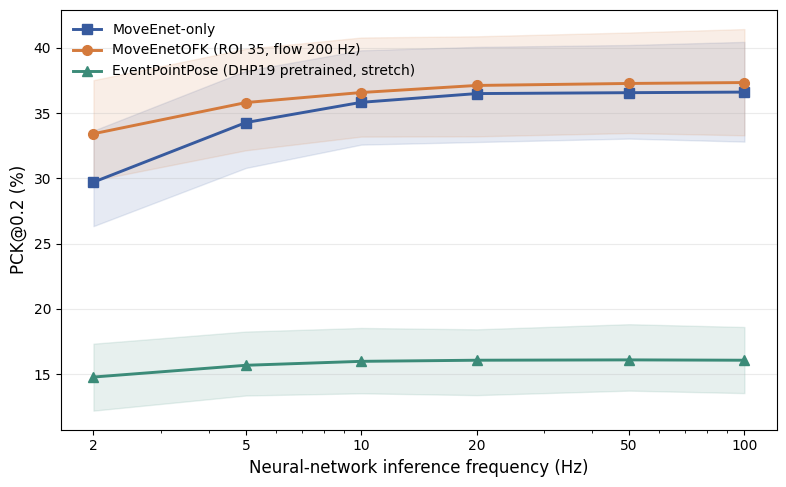

In [10]:
rates = sorted(summary.net_hz.unique())

def plot_accuracy_metric(metric, ylabel, basename, ci=None, title=None):
    fig,ax = plt.subplots(figsize=FIGSIZE)
    for method in METHODS:
        grp = summary[summary.method==method].set_index('net_hz').loc[rates]
        xx = np.asarray(rates,float)
        yy = grp[metric].to_numpy(dtype=float)
        ax.plot(xx,yy,color=COLORS[method],marker=MARKERS[method],
                linewidth=2.1,markersize=7,label=LABELS[method])
        if ci is not None and SHOW_CI:
            low,high = ci
            ax.fill_between(xx,grp[low].to_numpy(dtype=float),grp[high].to_numpy(dtype=float),
                            color=COLORS[method],alpha=.12)
    ax.set_xscale('log')
    ax.set_xticks(rates)
    ax.set_xticklabels(['{:g}'.format(x) for x in rates])
    ax.set_xlabel('Neural-network inference frequency (Hz)')
    ax.set_ylabel(ylabel)
    if title: ax.set_title(title)
    ax.grid(axis='y',alpha=.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    if SAVE_FIGURES:
        for ext in FIGURE_FORMATS:
            fig.savefig(OUT/'{}.{}'.format(basename,ext),dpi=DPI,bbox_inches='tight')
    plt.show()

plot_accuracy_metric('pck02_percent','PCK@0.2 (%)','pck02_vs_network_rate_3methods',
                     ci=('pck02_percent_ci_low','pck02_percent_ci_high'))

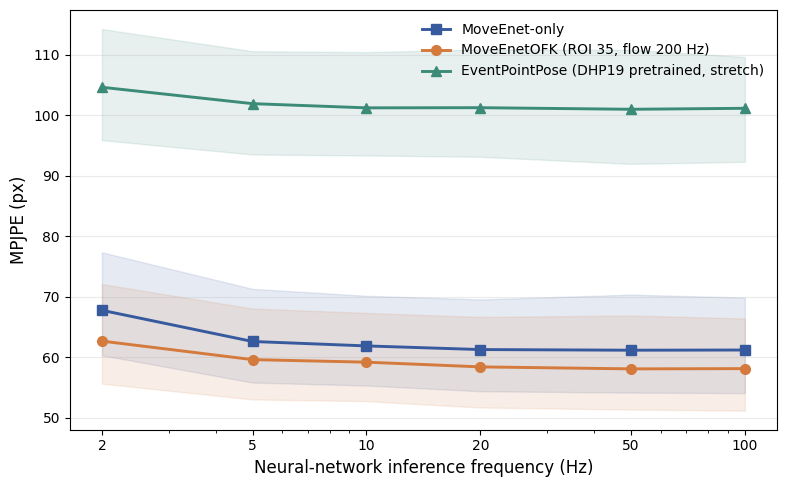

In [11]:
plot_accuracy_metric('mpjpe_px','MPJPE (px)','mpjpe_vs_network_rate_3methods',
                     ci=('mpjpe_px_ci_low','mpjpe_px_ci_high'))

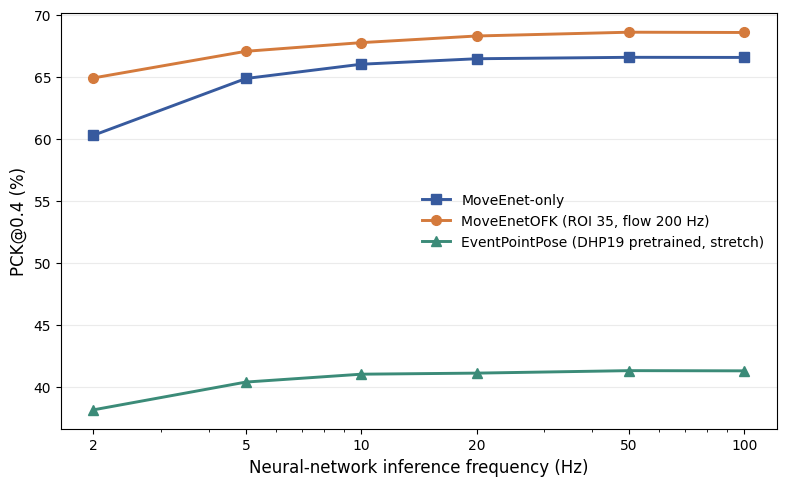

In [12]:
plot_accuracy_metric('pck04_percent','PCK@0.4 (%)','pck04_vs_network_rate_3methods')

## 10. Figures: paired differences against EventPointPose

Unlike overlapping individual-model confidence bands, these figures directly show paired differences. Positive MPJPE reduction and positive PCK improvement mean **MoveEnetOFK outperforms EventPointPose**; CIs crossing zero do not establish a consistent difference at that confidence level.

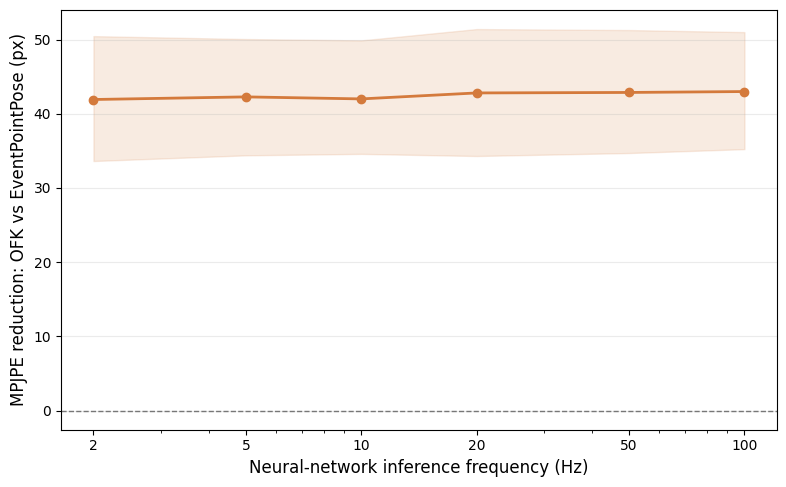

In [13]:
ofk_vs_epp = deltas[(deltas.method=='moveenet_ofk') & (deltas.baseline=='eventpointpose')].set_index('net_hz').loc[rates]
fig,ax=plt.subplots(figsize=FIGSIZE)
ax.axhline(0,color='#777777',linewidth=1,linestyle='--')
ax.plot(rates,ofk_vs_epp.mpjpe_improvement_px,color=COLORS['moveenet_ofk'],marker='o',linewidth=2)
if SHOW_CI:
    ax.fill_between(rates,ofk_vs_epp.mpjpe_ci_low.to_numpy(float),ofk_vs_epp.mpjpe_ci_high.to_numpy(float),
                    color=COLORS['moveenet_ofk'],alpha=.15)
ax.set_xscale('log');ax.set_xticks(rates);ax.set_xticklabels(['{:g}'.format(x) for x in rates])
ax.set_xlabel('Neural-network inference frequency (Hz)')
ax.set_ylabel('MPJPE reduction: OFK vs EventPointPose (px)')
ax.grid(axis='y',alpha=.25);fig.tight_layout()
if SAVE_FIGURES:
    for ext in FIGURE_FORMATS: fig.savefig(OUT/'paired_ofk_minus_epp_mpjpe.{}'.format(ext),dpi=DPI,bbox_inches='tight')
plt.show()

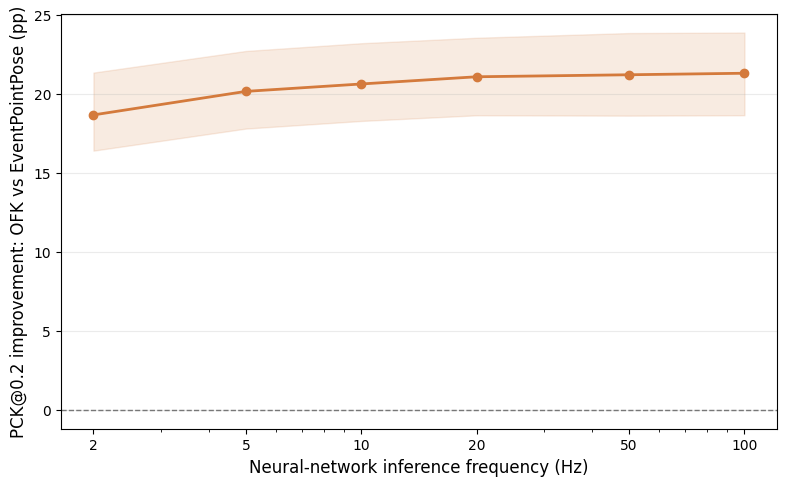

In [14]:
fig,ax=plt.subplots(figsize=FIGSIZE)
ax.axhline(0,color='#777777',linewidth=1,linestyle='--')
ax.plot(rates,ofk_vs_epp.pck02_improvement_pp,color=COLORS['moveenet_ofk'],marker='o',linewidth=2)
if SHOW_CI:
    ax.fill_between(rates,ofk_vs_epp.pck02_ci_low.to_numpy(float),ofk_vs_epp.pck02_ci_high.to_numpy(float),
                    color=COLORS['moveenet_ofk'],alpha=.15)
ax.set_xscale('log');ax.set_xticks(rates);ax.set_xticklabels(['{:g}'.format(x) for x in rates])
ax.set_xlabel('Neural-network inference frequency (Hz)')
ax.set_ylabel('PCK@0.2 improvement: OFK vs EventPointPose (pp)')
ax.grid(axis='y',alpha=.25);fig.tight_layout()
if SAVE_FIGURES:
    for ext in FIGURE_FORMATS: fig.savefig(OUT/'paired_ofk_minus_epp_pck02.{}'.format(ext),dpi=DPI,bbox_inches='tight')
plt.show()

## 11. Per-joint MPJPE at 5 Hz (diagnostic)

Use this plot to investigate which joints contribute most to the differences. **Do not interpret anatomical joint labels as validated** until projected-marker correspondence is verified.

method,"EventPointPose (DHP19 pretrained, stretch)","MoveEnetOFK (ROI 35, flow 200 Hz)",MoveEnet-only
joint_id,,,
0,124.75,68.53,71.72
1,112.72,48.85,52.61
2,107.45,50.50,54.22
3,124.61,58.44,62.10
4,109.71,58.35,62.12
5,84.08,59.60,61.61
6,83.56,54.18,56.52
7,159.21,86.50,90.59
8,106.23,79.56,83.52


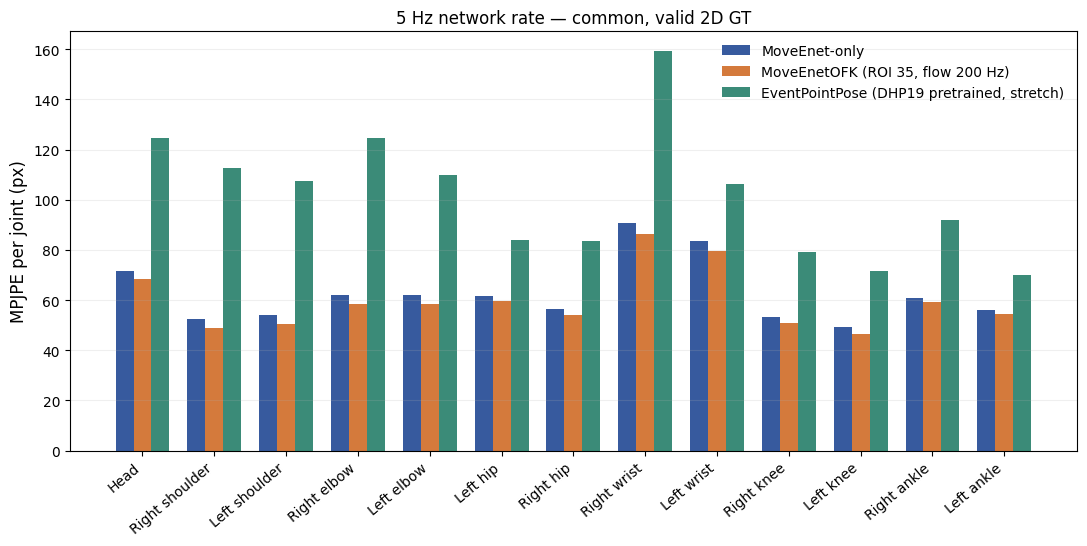

In [15]:
joint5 = joints[np.isclose(joints.net_hz,5.0)].copy()
require(not joint5.empty,'No 5Hz joint data')
per_joint = joint5.groupby(['joint_id','joint','method'],as_index=False).agg(
    err_sum=('sum_error_px','sum'),joint_n=('valid_mpjpe_joints','sum'))
per_joint['mpjpe_px'] = np.divide(per_joint.err_sum,per_joint.joint_n)
per_joint_pivot = per_joint.pivot(index='joint_id',columns='method',values='mpjpe_px').reindex(range(13))
display(per_joint_pivot.rename(columns=LABELS).round(2))
fig,ax = plt.subplots(figsize=(11,5.6))
x=np.arange(13); width=.25
for offset,method in zip((-1,0,1),METHODS):
    ax.bar(x+offset*width,per_joint_pivot[method].to_numpy(float),width=width,
           color=COLORS[method],label=LABELS[method])
ax.set_xticks(x);ax.set_xticklabels(JOINT_NAMES,rotation=40,ha='right')
ax.set_ylabel('MPJPE per joint (px)');ax.set_title('5 Hz network rate — common, valid 2D GT')
ax.grid(axis='y',alpha=.2);ax.legend(frameon=False)
fig.tight_layout()
if SAVE_FIGURES:
    for ext in FIGURE_FORMATS: fig.savefig(OUT/'per_joint_mpjpe_5hz_3methods.{}'.format(ext),dpi=DPI,bbox_inches='tight')
plt.show()

## 12. Joint-order sanity check — one recording and three paired native timestamps

This is a **near-time** rather than exact-time comparison. The displayed GT uses EventPointPose's native timestamp; each prediction uses its own native timestamp, separated by up to 2.5 ms. Index numbers are displayed without inventing skeleton connectivity. Anatomical correspondence remains unverified.

Mapping diagnostic: luna/box_f1, EPP t=0.505s, 13 valid GT joints
Native times (seconds): {'moveenet_only': 0.50414, 'moveenet_ofk': 0.50414, 'eventpointpose': 0.505}
Provisional mapped marker names: {'Head': 'P1:HEDO', 'Right shoulder': 'P1:RCLO', 'Left shoulder': 'P1:LCLO', 'Right elbow': 'P1:RHUO', 'Left elbow': 'P1:LHUO', 'Left hip': 'P1:LFEP', 'Right hip': 'P1:RFEP', 'Right wrist': 'P1:RRAO', 'Left wrist': 'P1:LRAO', 'Right knee': 'P1:RFEO', 'Left knee': 'P1:LFEO', 'Right ankle': 'P1:RTIO', 'Left ankle': 'P1:LTIO'}


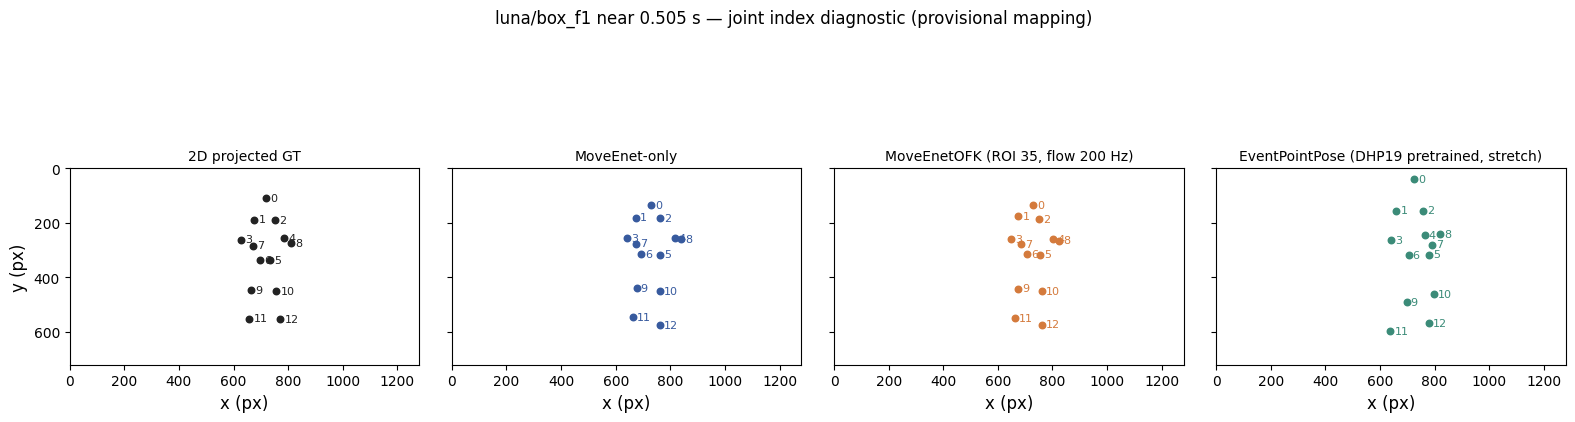

In [16]:
# Use one-to-one matched original 5 Hz prediction outputs; no predicted pose is interpolated.
example_rows = manifest[(manifest.subject == 'luna') & (manifest.sequence == 'box_f1')]
example = example_rows.iloc[0] if len(example_rows) else manifest.iloc[0]
subject,sequence,tag = example.subject,example.sequence,'0.2'
stem = '{}__{}__atis-s'.format(subject,sequence)
move_dir = MOVEENET_BASE/'raw'/'fp_0p005'/('np_'+tag.replace('.','p'))
visual_paths = {
    'moveenet_only': move_dir/'{}_moveenet_only_np_{}_fp_0p005.csv'.format(stem,tag.replace('.','p')),
    'moveenet_ofk': move_dir/'{}_moveenet_ofk_np_{}_fp_0p005.csv'.format(stem,tag.replace('.','p')),
    'eventpointpose': EPP_BASE/'raw'/'{}__epp_stretch_np_{}.csv'.format(stem,tag.replace('.','p')),
}
vis_ts,vis_pred,_,_,_,vis_lags = align_three({m:load_prediction(visual_paths[m]) for m in METHODS},visual_paths)
raw_t,raw_gt,raw_valid,_ = load_gt(Path(example.ground_truth))
vis_gt,vis_mask,_ = masked_linear_gt(vis_ts,raw_t,raw_gt,raw_valid)
# Prefer an early time with at least 10 usable joints; fallback to best-covered frame.
coverage_per_frame = vis_mask.sum(axis=1)
preferred = np.flatnonzero((vis_ts >= 0.5) & (coverage_per_frame >= 10))
frame_idx = int(preferred[0]) if len(preferred) else int(np.argmax(coverage_per_frame))
print('Mapping diagnostic: {}/{}, EPP t={:.3f}s, {} valid GT joints'.format(
    subject,sequence,vis_ts[frame_idx],int(coverage_per_frame[frame_idx])))
print('Native times (seconds):', {m:round(float(vis_pred[m][0][frame_idx]),6) for m in METHODS})
for schema,examples in GT_SCHEMAS.items():
    if str(example.ground_truth) in examples:
        raw_names = [name.rsplit('_',1)[0] for name in schema[::2]]
        print('Provisional mapped marker names:',
              {JOINT_NAMES[j]: raw_names[PROJECTION_TO_MOVEENET[j]] for j in range(13)})
        break
fig,axes=plt.subplots(1,4,figsize=(16,5),sharex=True,sharey=True)
series=[('2D projected GT',vis_gt[frame_idx],vis_mask[frame_idx],'#222222')]
for method in METHODS:
    series.append((LABELS[method],vis_pred[method][1][frame_idx],
                   np.isfinite(vis_pred[method][1][frame_idx]).all(axis=1),COLORS[method]))
for ax,(label,pts,valid,color) in zip(axes,series):
    ax.scatter(pts[valid,0],pts[valid,1],color=color,s=22)
    for j,(x,y) in enumerate(pts):
        if valid[j]: ax.annotate(str(j),(x,y),xytext=(3,-2),textcoords='offset points',fontsize=8,color=color)
    ax.set_xlim(0,SENSOR_WIDTH)
    ax.set_ylim(SENSOR_HEIGHT,0)
    ax.set_aspect('equal',adjustable='box')
    ax.set_title(label,fontsize=10)
    ax.set_xlabel('x (px)')
axes[0].set_ylabel('y (px)')
fig.suptitle('{}/{} near {:.3f} s — joint index diagnostic (provisional mapping)'.format(
    subject,sequence,vis_ts[frame_idx]),fontsize=12)
fig.tight_layout()
if SAVE_FIGURES:
    for ext in FIGURE_FORMATS:
        fig.savefig(OUT/'joint_mapping_diagnostic_{}.{}'.format(stem,ext),dpi=DPI,bbox_inches='tight')
plt.show()


## 13. Summary and limitations

This notebook reports exactly what the CSVs support; it does not infer why one algorithm performs better or worse. Before using its absolute accuracy values in the paper, independently verify (i) projected GT marker mapping against the common 13-joint skeleton convention, (ii) whether EventPointPose outputs those joints in that same order, and (iii) event/GT temporal alignment. One-to-one pairing tolerates up to 2.5ms native-time difference and **GT is interpolated separately at every method timestamp**. Full-run audit success establishes **file completeness**, not anatomical or synchronization validity.

**Important:** All three curves are re-evaluated on the common three-method subset, which is the correct population for direct comparative statements. Their numerical values need not exactly match the earlier two-method corrected ExpA report.

In [17]:
print('Sequences:',len(manifest),'| network periods:',len(NETWORK_PERIODS),
      '| evaluated method/rate/sequence runs:',len(samples))
print('EPP runs audited OK:',len(audit))
print('GT out-of-frame marker observations:',int(gt_quality.gt_out_of_frame_annotations.sum()))
print('GT non-finite marker observations:',int(gt_quality.gt_nonfinite_annotations.sum()))
print('Common output rows over all recording/rate pairs:',int(alignment.common_rows.sum()))
print('Worst time overlap fraction:',float(alignment.common_fraction_of_shortest.min()))
print('Max native-time difference to EPP matched frame:',float(alignment.max_timestamp_alignment_error_s.max()),'s')
print('Median mean absolute lag (MoveEnet-only):',float(alignment.only_mean_absolute_pair_lag_ms.median()),'ms')
print('Median mean absolute lag (MoveEnetOFK):',float(alignment.ofk_mean_absolute_pair_lag_ms.median()),'ms')
print('\nThree-way PCK@0.2 and MPJPE summary:')
display(summary[['net_hz','method','mpjpe_px','pck02_percent','pck04_percent']].round(3))
print('\nPaper caveat: GT marker order, EventPointPose joint convention and temporal offset remain provisional.')
print('Output directory:',OUT)

Sequences: 59 | network periods: 6 | evaluated method/rate/sequence runs: 1062
EPP runs audited OK: 354
GT out-of-frame marker observations: 2678
GT non-finite marker observations: 0
Common output rows over all recording/rate pairs: 718683
Worst time overlap fraction: 0.9665822784810126
Max native-time difference to EPP matched frame: 0.0024900000000016576 s
Median mean absolute lag (MoveEnet-only): 1.2331419705949807 ms
Median mean absolute lag (MoveEnetOFK): 1.2331419705949807 ms

Three-way PCK@0.2 and MPJPE summary:


,net_hz,method,mpjpe_px,pck02_percent,pck04_percent
0,2.0,eventpointpose,104.616,14.769,38.132
1,2.0,moveenet_ofk,62.696,33.422,64.892
2,2.0,moveenet_only,67.781,29.710,60.270
3,5.0,eventpointpose,101.910,15.671,40.372
4,5.0,moveenet_ofk,59.636,35.813,67.041
5,5.0,moveenet_only,62.632,34.281,64.848
6,10.0,eventpointpose,101.216,15.973,41.007
7,10.0,moveenet_ofk,59.215,36.583,67.739
8,10.0,moveenet_only,61.899,35.831,65.998
9,20.0,eventpointpose,101.243,16.058,41.093



Paper caveat: GT marker order, EventPointPose joint convention and temporal offset remain provisional.
Output directory: /data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/analysis_2d_gt_expa_epp_3methods_v2_native_time
